# Lab 7 · Example A — IMDB Sentiment with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Goal.** Read a movie review and classify it as **positive** or **negative** (binary). You will
turn text into integer indices, pad them, learn **word embeddings**, summarise each review with a
**Bidirectional LSTM**, and decide with a **sigmoid** output.

---
Replace every `None  # TODO (Qn)` with the correct value/code. Run top to bottom.
*(Needs internet once to download the IMDB dataset — works on Colab.)*


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

IMDB reviews come **already encoded as integer indices**. Keep the top `num_words` words and pad
every review to `maxlen` tokens.

*Hints:* keep the 10000 most frequent words; pad to length 200.


In [2]:
# Q1a) hyperparameters
num_words = 10000     # TODO (Q1a): keep the 10000 most frequent words
maxlen    = 200     # TODO (Q1a): fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42)   # TODO (Q1c): 0.2

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)


#### Quick check *(given)*

In [3]:
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print("Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)")

Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)


## Task 2 — Build the model

Stack: **Embedding** (vocabulary `num_words`, 128-dim vectors) → **Bidirectional LSTM(64)**
returning a single summary vector → **Dropout(0.5)** → **Dense(1, sigmoid)**.

*Hints:* `Embedding(input_dim=num_words, output_dim=128)`; a bidirectional LSTM that returns one
vector uses `return_sequences=False`; one output neuron with a sigmoid gives a probability.


In [4]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))   # TODO (Q2c): 0.5

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation= 'sigmoid'))   # TODO (Q2d): 1, 'sigmoid'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2e.** The Embedding layer shows **1,280,000** parameters. Show why with
`num_words × embed_dim`. Why does this one layer hold most of the model's parameters?

> **Your answer (Q2e):** 1,280,000 = ____ × ____ ; it dominates because ____.


## Task 3 — Compile and train

Use the **adam** optimiser, **binary crossentropy** loss (one sigmoid output), track accuracy.
Train 5 epochs, batch size 64, validating on `(X_val, y_val)`.


In [5]:
# Q3a) compile for binary classification
model.compile(optimizer='adam',
              loss='binary_crossentropy',              # TODO (Q3a): 'binary_crossentropy'
              metrics=['accuracy'])

# Q3b) train
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,          # TODO (Q3b): 5
                    batch_size=64)      # TODO (Q3b): 64

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 28ms/step - accuracy: 0.7804 - loss: 0.4578 - val_accuracy: 0.8530 - val_loss: 0.3679
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8974 - loss: 0.2647 - val_accuracy: 0.8744 - val_loss: 0.3286
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9263 - loss: 0.1935 - val_accuracy: 0.8724 - val_loss: 0.3311
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9445 - loss: 0.1517 - val_accuracy: 0.8664 - val_loss: 0.3721
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9565 - loss: 0.1220 - val_accuracy: 0.8326 - val_loss: 0.5097


## Task 4 — Evaluate and plot *(fill the blanks)*

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8264 - loss: 0.5276
Test accuracy: 82.64%


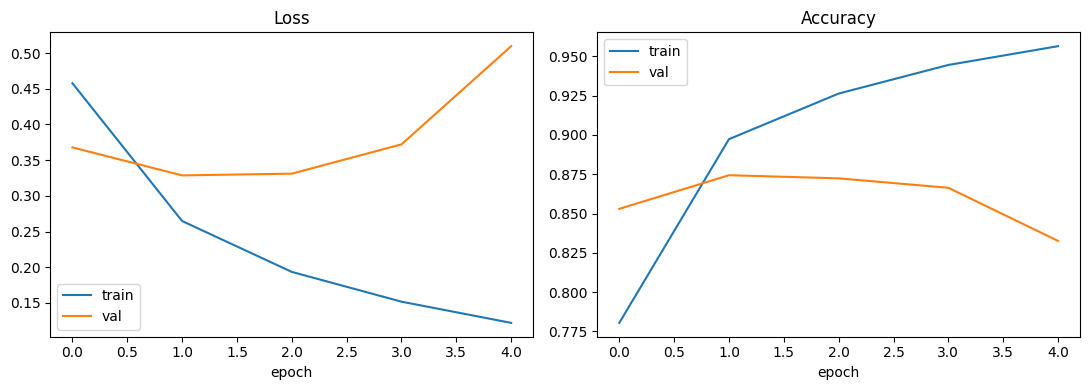

In [6]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 86-88%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Predict on your own text *(fill the blanks)*

IMDB reserves indices 0–2 (pad / start / unknown), so real words are **offset by 3**.


In [7]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
    padded = pad_sequences([enc], maxlen=maxlen)
    p = model.predict(padded, verbose=0)[0][0]
    # Q5) threshold the sigmoid at 0.5
    return "Positive" if p >= 0.5 else "Negative"   # TODO (Q5): 0.5

for r in ["this film was absolutely wonderful and moving",
          "a boring dull waste of time"]:
    print(f"{predict_sentiment(r):8s} <- {r}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time


## Task 6 — Short questions *(write answers here)*

1. Why do we **pad** every review to the same length?
2. What does the **Embedding** layer do that one-hot encoding of words would not?
3. Why `return_sequences=False` here (unlike the music lab)?
4. Why `sigmoid` + `binary_crossentropy` instead of `softmax` + `categorical_crossentropy`?
5. In your accuracy plot, does validation loss start rising? What does that indicate, and what
   does `Dropout(0.5)` do about it?

> **Your answers:**
1. Batch tensor must be rectangular so we truncate if it is longer than the specified length or else pad with zero if it lesser than the specified length
2. Embedding layer is a lookup table mapping each index to a dense, trainable
vector. As the previous and next words are relevant to the context, Embedding places similar words next to each other where as One hot encoding treats them as completely different words
3. only the final summary vector
4. One class.  `softmax` + `categorical_crossentropy` could be used for multi-class
5. Yes. Overfitting: the model starts memorising the training reviews. This is
exactly why we use Dropout, and why we could add early stopping.
